In [1]:
# Parameters
ticker = "AAPL"  # Stock ticker to analyze
start_date = "2024-01-01"  # Analysis start date
end_date = "2024-12-31"  # Analysis end date
db_path = "data/data.db"

In [2]:
# Parameters
ticker = "AAPL"
start_date = "2024-06-01"
end_date = "2024-11-30"


In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import sqlite3
import papermill as pm
from datetime import datetime, timedelta
from tqdm import tqdm
from pathlib import Path

In [4]:
ticker = ticker.strip().upper()
start = pd.to_datetime(start_date, errors="raise")
end = pd.to_datetime(end_date, errors="raise")

if not ticker:
    raise ValueError("Ticker cannot be empty.")

if start > end:
    raise ValueError("start_date must be on or before end_date.")

print("Ticker:", ticker)
print("Start date:", start.date())
print("End date:", end.date())
print("Database path:", Path(db_path).resolve())

Ticker: AAPL
Start date: 2024-06-01
End date: 2024-11-30
Database path: /Users/anouksha/UCB-MFE-python-preprogram-2026-winter/Homeworks/HW2/Anouksha_Bansal/data/data.db


In [5]:

conn = sqlite3.connect(db_path)

try:
    df = pd.read_sql_query("SELECT * FROM ohlc_hw_cleaned", conn)
finally:
    conn.close()

df["ticker"] = df["ticker"].astype("string").str.strip().str.upper()
df["ts"] = pd.to_datetime(df["ts"], errors="coerce")

print("Data loaded successfully.")
print("Total rows:", len(df))

Data loaded successfully.
Total rows: 338785


In [6]:
stock_df = df.loc[
    (df["ticker"] == ticker)
    & (df["ts"] >= start)
    & (df["ts"] <= end)
].copy()

stock_df = stock_df.sort_values("ts").reset_index(drop=True)

if stock_df.empty:
    raise ValueError(
        f"No data found for {ticker} from "
        f"{start.date()} to {end.date()}. "
        "Check the ticker and date range."
    )

if stock_df["ts"].duplicated().any():
    raise ValueError(
        f"Duplicate trading dates found for {ticker}."
    )

print(
    f"{ticker} from {start.date()} to {end.date()}: "
    f"{len(stock_df)} trading days"
)

print("Actual first observation:", stock_df["ts"].min().date())
print("Actual last observation:", stock_df["ts"].max().date())


AAPL from 2024-06-01 to 2024-11-30: 84 trading days
Actual first observation: 2024-06-03
Actual last observation: 2024-10-18


In [7]:

print("First five rows:")
display(stock_df.head())

print("Last five rows:")
display(stock_df.tail())

First five rows:


,ts,open,high,low,close,adj_close,volume,ticker,repaired_open,repaired_high,repaired_low,repaired_close,repaired_adj_close,volume_filled_zero,extreme_return_flag,repair_notes
0,2024-06-03,192.90,194.99,192.52,194.03,193.81,50080539,AAPL,0,0,0,0,0,0,0,
1,2024-06-04,194.64,195.32,193.03,194.35,194.13,47471445,AAPL,0,0,0,0,0,0,0,
2,2024-06-05,195.40,196.90,194.87,195.87,195.64,54156785,AAPL,0,0,0,0,0,0,0,
3,2024-06-06,195.69,196.50,194.17,194.48,194.26,41181753,AAPL,0,0,0,0,0,0,0,
4,2024-06-07,194.65,196.94,194.14,196.89,196.66,53103912,AAPL,0,0,0,0,0,0,0,


Last five rows:


,ts,open,high,low,close,adj_close,volume,ticker,repaired_open,repaired_high,repaired_low,repaired_close,repaired_adj_close,volume_filled_zero,extreme_return_flag,repair_notes
79,2024-10-14,228.70,231.73,228.60,231.30,231.30,39882100,AAPL,0,0,0,0,0,0,0,
80,2024-10-15,233.61,237.49,232.37,233.85,233.85,64751400,AAPL,0,0,0,0,0,0,0,
81,2024-10-16,231.60,232.12,229.84,231.78,231.78,34082240,AAPL,0,0,0,0,0,0,0,
82,2024-10-17,233.43,233.85,230.52,232.15,232.15,32993810,AAPL,0,0,0,0,0,0,0,
83,2024-10-18,236.18,236.18,234.01,235.00,235.00,45441281,AAPL,0,0,0,0,0,0,0,


In [8]:
prices = pd.to_numeric(stock_df["adj_close"], errors="coerce")

valid_prices = prices[
    np.isfinite(prices) & (prices > 0)
]

n_prices = len(valid_prices)
n_returns = max(n_prices - 1, 0)

print("Valid adjusted closing prices:", n_prices)
print("Potential daily returns:", n_returns)

Valid adjusted closing prices: 84
Potential daily returns: 83


In [9]:

def calculate_returns(prices: pd.Series) -> pd.Series:
    """Calculate daily log returns."""
    prices = pd.to_numeric(prices, errors="coerce")

    valid_prices = prices.where(
        np.isfinite(prices) & (prices > 0)
    )

    returns = np.log(valid_prices / valid_prices.shift(1))
    return returns


stock_df["daily_return"] = calculate_returns(stock_df["adj_close"])

display(stock_df[["ts", "adj_close", "daily_return"]].head(10))


,ts,adj_close,daily_return
0,2024-06-03,193.81,NaN
1,2024-06-04,194.13,0.001650
2,2024-06-05,195.64,0.007748
3,2024-06-06,194.26,-0.007079
4,2024-06-07,196.66,0.012279
5,2024-06-10,192.90,-0.019304
6,2024-06-11,206.91,0.070112
7,2024-06-12,212.82,0.028163
8,2024-06-13,213.99,0.005483
9,2024-06-14,212.24,-0.008212


In [10]:

# ROLLING VOLATILITY

def calculate_volatility(returns: pd.Series, window: int = 20) -> pd.Series:
    """Calculate annualized rolling volatility."""
    if window < 1:
        raise ValueError("window must be at least 1.")

    annualized_volatility = returns.rolling(window=window, min_periods=window).std() * np.sqrt(252)

    return annualized_volatility


stock_df["rolling_volatility"] = calculate_volatility(stock_df["daily_return"], window=20)

display(stock_df[["ts", "daily_return", "rolling_volatility"]].tail(10))


,ts,daily_return,rolling_volatility
74,2024-10-03,-0.002390,9.196617
75,2024-10-04,0.004995,9.196544
76,2024-10-07,-0.022789,9.195974
77,2024-10-08,0.018237,9.196172
78,2024-10-09,0.016561,9.196288
79,2024-10-14,0.007638,9.196288
80,2024-10-15,0.010964,9.196281
81,2024-10-16,-0.008891,9.196368
82,2024-10-17,0.001595,9.196361
83,2024-10-18,0.012202,9.195713


In [11]:

def calculate_max_drawdown(prices: pd.Series) -> pd.Series:
    """Return per-date drawdown from the running price peak."""
    prices = pd.to_numeric(prices, errors="coerce")

    valid_prices = prices.where(np.isfinite(prices) & (prices > 0))

    cum_max = valid_prices.cummax()
    drawdown = (valid_prices - cum_max) / cum_max

    return drawdown


stock_df["drawdown"] = calculate_max_drawdown(stock_df["adj_close"])

maximum_drawdown = stock_df["drawdown"].min()

print("Maximum drawdown:", f"{maximum_drawdown:.2%}"
      if pd.notna(maximum_drawdown) else "N/A")

display(stock_df[["ts", "adj_close", "drawdown"]].tail(10))

Maximum drawdown: -85.14%


,ts,adj_close,drawdown
74,2024-10-03,225.67,-0.844933
75,2024-10-04,226.80,-0.844157
76,2024-10-07,221.69,-0.847668
77,2024-10-08,225.77,-0.844865
78,2024-10-09,229.54,-0.842274
79,2024-10-14,231.30,-0.841065
80,2024-10-15,233.85,-0.839313
81,2024-10-16,231.78,-0.840735
82,2024-10-17,232.15,-0.840481
83,2024-10-18,235.00,-0.838522


In [12]:

def calculate_sharpe_ratio(returns: pd.Series, risk_free_rate: float = 0.02) -> float:
    """Calculate the annualized Sharpe ratio."""
    valid_returns = returns.dropna()
    valid_returns = valid_returns[np.isfinite(valid_returns)]

    if len(valid_returns) < 2:
        return np.nan

    daily_std = valid_returns.std(ddof=1)

    if not np.isfinite(daily_std) or daily_std == 0:
        return np.nan

    annualized_return = valid_returns.mean() * 252
    annualized_volatility = daily_std * np.sqrt(252)

    return (annualized_return - risk_free_rate) / annualized_volatility


sharpe_ratio = calculate_sharpe_ratio(
    stock_df["daily_return"], risk_free_rate=0.02
)

print(
    "Annualized Sharpe ratio:",
    f"{sharpe_ratio:.4f}" if pd.notna(sharpe_ratio) else "N/A"
)

Annualized Sharpe ratio: 0.0884


In [13]:
stock_df["ma_50"] = stock_df["adj_close"].rolling(window=50,min_periods=50).mean()

mean_volatility = stock_df["rolling_volatility"].mean()

print("Mean 20-day rolling volatility:",
      f"{mean_volatility:.2%}" if pd.notna(mean_volatility) else "N/A")

print("50-day moving average available:",
      stock_df["ma_50"].notna().sum(), "observations")

Mean 20-day rolling volatility: 543.78%
50-day moving average available: 35 observations


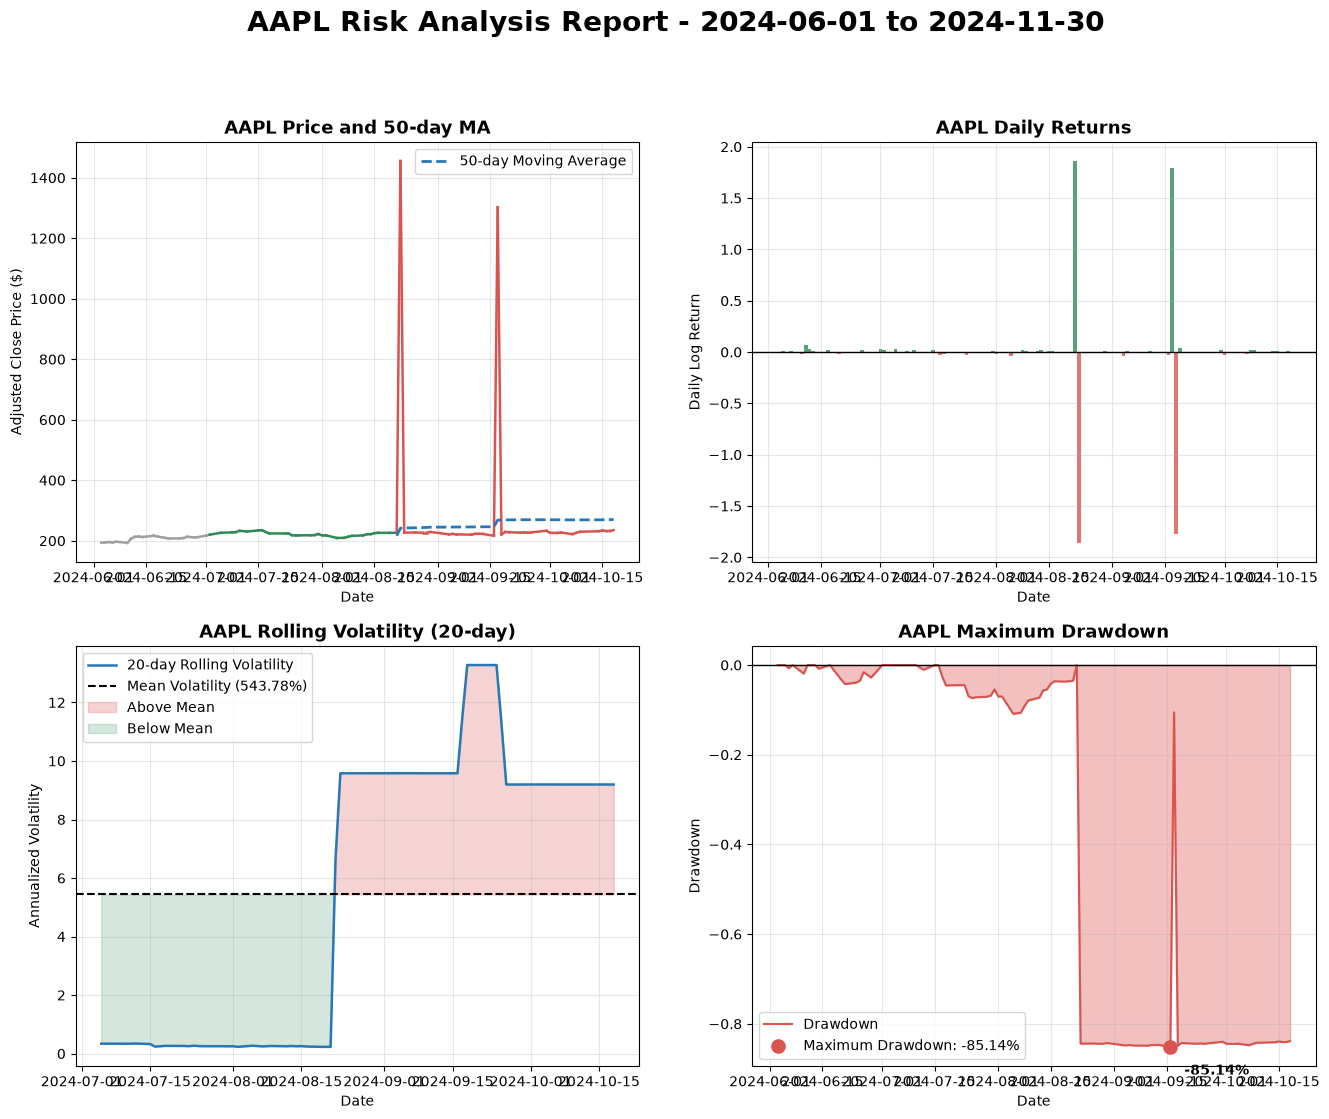

In [14]:

fig, axes = plt.subplots(2, 2, figsize=(16, 12))

ax1, ax2 = axes[0, 0], axes[0, 1]
ax3, ax4 = axes[1, 0], axes[1, 1]

GREEN = "#2E8B57"
RED = "#D9534F"
BLUE = "#2878B5"
GRAY = "#A0A0A0"

fig.suptitle(
    f"{ticker} Risk Analysis Report - {start_date} to {end_date}",
    fontsize=20,
    fontweight="bold",
    y=0.99
)

dates = stock_df["ts"]
prices = stock_df["adj_close"]
volatility = stock_df["rolling_volatility"]

for i in range(1, len(stock_df)):
    current_vol = volatility.iloc[i]

    if pd.isna(current_vol) or pd.isna(mean_volatility):
        line_color = GRAY
    elif current_vol > mean_volatility:
        line_color = RED
    else:
        line_color = GREEN

    ax1.plot(
        dates.iloc[i-1:i+1],
        prices.iloc[i-1:i+1],
        color=line_color,
        linewidth=1.8
    )

# Plot 50-day moving average
ax1.plot(
    dates,
    stock_df["ma_50"],
    color=BLUE,
    linewidth=2,
    linestyle="--",
    label="50-day Moving Average"
)

ax1.set_title(f"{ticker} Price and 50-day MA", fontsize=13, fontweight="bold")
ax1.set_xlabel("Date")
ax1.set_ylabel("Adjusted Close Price ($)")
ax1.grid(True, alpha=0.3)
ax1.legend()

daily_returns = stock_df["daily_return"]

return_colors = [
    GREEN if value >= 0 else RED
    for value in daily_returns
]

ax2.bar(
    dates,
    daily_returns,
    color=return_colors,
    width=1.0,
    alpha=0.8
)

ax2.axhline(0, color="black", linewidth=1)

ax2.set_title(f"{ticker} Daily Returns", fontsize=13, fontweight="bold")
ax2.set_xlabel("Date")
ax2.set_ylabel("Daily Log Return")
ax2.grid(True, alpha=0.3)

ax3.plot(
    dates,
    volatility,
    color=BLUE,
    linewidth=1.8,
    label="20-day Rolling Volatility"
)

if pd.notna(mean_volatility):
    ax3.axhline(
        mean_volatility,
        color="black",
        linestyle="--",
        linewidth=1.5,
        label=f"Mean Volatility ({mean_volatility:.2%})"
    )

    ax3.fill_between(
        dates,
        volatility,
        mean_volatility,
        where=(volatility > mean_volatility),
        color=RED,
        alpha=0.25,
        interpolate=True,
        label="Above Mean"
    )


    ax3.fill_between(
        dates,
        volatility,
        mean_volatility,
        where=(volatility < mean_volatility),
        color=GREEN,
        alpha=0.20,
        interpolate=True,
        label="Below Mean"
    )

ax3.set_title(
    f"{ticker} Rolling Volatility (20-day)",
    fontsize=13,
    fontweight="bold"
)
ax3.set_xlabel("Date")
ax3.set_ylabel("Annualized Volatility")
ax3.grid(True, alpha=0.3)
ax3.legend()

drawdown = stock_df["drawdown"]

ax4.plot(
    dates,
    drawdown,
    color=RED,
    linewidth=1.5,
    label="Drawdown"
)

ax4.fill_between(
    dates, drawdown, 0,
    where=(drawdown <= 0),
    color="#F4A6A6",
    alpha=0.25
)

ax4.fill_between(
    dates, drawdown, 0,
    where=(drawdown <= 0),
    color="#E57373",
    alpha=0.20
)

ax4.fill_between(
    dates, drawdown, 0,
    where=(drawdown <= 0),
    color=RED,
    alpha=0.12
)

if drawdown.notna().any():
    max_dd_date = drawdown.idxmin()
    max_dd_value = drawdown.loc[max_dd_date]
    max_dd_timestamp = stock_df.loc[max_dd_date, "ts"]

    ax4.scatter(
        max_dd_timestamp,
        max_dd_value,
        color=RED,
        s=90,
        zorder=5,
        label=f"Maximum Drawdown: {max_dd_value:.2%}"
    )

    ax4.annotate(
        f"{max_dd_value:.2%}",
        xy=(max_dd_timestamp, max_dd_value),
        xytext=(10, -20),
        textcoords="offset points",
        fontsize=10,
        fontweight="bold"
    )

ax4.axhline(0, color="black", linewidth=1)

ax4.set_title(
    f"{ticker} Maximum Drawdown",
    fontsize=13,
    fontweight="bold"
)
ax4.set_xlabel("Date")
ax4.set_ylabel("Drawdown")
ax4.grid(True, alpha=0.3)
ax4.legend()

In [15]:
valid_prices = pd.to_numeric(stock_df["adj_close"], errors="coerce")

valid_prices = valid_prices[np.isfinite(valid_prices) & (valid_prices > 0)]

if len(valid_prices) < 2:
    total_return = np.nan
else:
    first_price = valid_prices.iloc[0]
    last_price = valid_prices.iloc[-1]
    total_return = last_price / first_price - 1

print(
    "Total Return:",
    f"{total_return:+.2%}" if pd.notna(total_return) else "N/A"
)

valid_returns = stock_df["daily_return"].dropna()
valid_returns = valid_returns[np.isfinite(valid_returns)]

n = len(valid_returns)

if n == 0:
    annualized_return = np.nan
else:
    annualized_return = np.exp(
        valid_returns.sum() * 252 / n
    ) - 1

print(
    "Annualized Return:",
    f"{annualized_return:+.2%}"
    if pd.notna(annualized_return) else "N/A"
)

if len(valid_returns) < 2:
    annualized_volatility = np.nan
else:
    daily_std = valid_returns.std(ddof=1)
    annualized_volatility = daily_std * np.sqrt(252)

print(
    "Annualized Volatility:",
    f"{annualized_volatility:.2%}"
    if pd.notna(annualized_volatility) else "N/A"
)

sharpe_ratio = calculate_sharpe_ratio(
    stock_df["daily_return"],
    risk_free_rate=0.02
)

drawdown = calculate_max_drawdown(stock_df["adj_close"])
maximum_drawdown = drawdown.min()

print(
    "Sharpe Ratio:",
    f"{sharpe_ratio:.2f}" if pd.notna(sharpe_ratio) else "N/A"
)

print(
    "Maximum Drawdown:",
    f"{maximum_drawdown:.2%}"
    if pd.notna(maximum_drawdown) else "N/A"
)


# DAILY RETURN STATISTICS

# Best and worst daily returns
best_day = valid_returns.max() if len(valid_returns) else np.nan
worst_day = valid_returns.min() if len(valid_returns) else np.nan

# Percentage of positive days, including zero-return days in denominator
if len(valid_returns) == 0:
    positive_days = np.nan
else:
    positive_days = (valid_returns > 0).sum() / len(valid_returns)

# Average positive return
up_days = valid_returns[valid_returns > 0]

if len(up_days) == 0:
    average_up_day = np.nan
else:
    average_up_day = up_days.mean()

# Average negative return
down_days = valid_returns[valid_returns < 0]

if len(down_days) == 0:
    average_down_day = np.nan
else:
    average_down_day = down_days.mean()

print("Best Day:", f"{best_day:+.2%}" if pd.notna(best_day) else "N/A")
print("Worst Day:", f"{worst_day:+.2%}" if pd.notna(worst_day) else "N/A")
print("Positive Days:", f"{positive_days:.1%}" if pd.notna(positive_days) else "N/A")
print("Average Up Day:", f"{average_up_day:+.2%}" if pd.notna(average_up_day) else "N/A")
print("Average Down Day:", f"{average_down_day:+.2%}" if pd.notna(average_down_day) else "N/A")


Total Return: +21.25%
Annualized Return: +79.51%
Annualized Volatility: 639.58%
Sharpe Ratio: 0.09
Maximum Drawdown: -85.14%
Best Day: +186.07%
Worst Day: -185.87%
Positive Days: 60.2%
Average Up Day: +8.44%
Average Down Day: -13.43%


In [16]:
import json

portfolio_metrics = {
    "ticker": ticker,
    "avg_daily_return": valid_returns.mean() if len(valid_returns) else np.nan,
    "avg_volatility": stock_df["rolling_volatility"].mean(),
    "max_drawdown": maximum_drawdown,
    "sharpe_ratio": sharpe_ratio,
    "total_return": total_return
}

print("PORTFOLIO_METRICS:" + json.dumps(portfolio_metrics))

PORTFOLIO_METRICS:{"ticker": "AAPL", "avg_daily_return": 0.0023217736919458162, "avg_volatility": 5.437751783917605, "max_drawdown": -0.8513581256039972, "sharpe_ratio": 0.08835253758434171, "total_return": 0.21252773334709252}
